# Week 2 — Regularisation: Lasso, Ridge, Elastic Net

**The task.** Predict which Polish firms go bankrupt within 3 years. Each row is one firm and its
financial ratios. The `class` column is 1 if the firm went bankrupt and 0 if it survived.

**The problem** When several columns carry almost the same information, an unpenalised model
can't separate their effects. Small changes in the data move weight from one column to another, so the
coefficients are unstable. A **penalty** adds a cost for large coefficients, which keeps them small; the lasso
penalty also sets some coefficients to exactly zero, so the model **selects** a subset of columns.

**Research question:** RQ2 — which families of ratios carry the signal, and does that change with
the forecast horizon?

**Why logistic regression?** The target is binary (bankrupt or not), and logistic regression outputs a
probability between 0 and 1. Lasso, ridge and elastic net are penalties that can be added to any
regression; here logistic regression is the model they are added to.

## Datasets used

- **Polish Companies Bankruptcy** — UCI Machine Learning Repository, DOI [10.24432/C5F600](https://doi.org/10.24432/C5F600).
  Polish firms, 2000–2013. Each row is one firm: 64 financial ratios, and `class` = 1 if it went bankrupt.
  - **Main file:** `polish_predict_3y.csv` — 10,416 firms after removing duplicates, 493 bankrupt (4.7%).
    Used in Steps 1–9.
  File naming: `polish_predict_3y.csv` = ratios used to predict bankruptcy **3 years ahead**
  (UCI's original `3year.arff`; our files are renamed by forecast distance).
  - **All five horizons:** `polish_predict_1y.csv` … `polish_predict_5y.csv` — Step 10 only (RQ2 across horizons).
    Each file is modelled separately, never mixed.
- **Taiwanese Bankruptcy Prediction** — UCI, DOI [10.24432/C5004D](https://doi.org/10.24432/C5004D).
  6,819 Taiwanese firms, 1999–2009: 95 financial ratios, and `Bankrupt?` = 1 if it went bankrupt (3.2%).
  - **File used:** `taiwanese_bankruptcy.csv` — Step 11 only, as a contrast with fewer bankrupt firms per column.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

DATA = Path("../Dataset_new/CSV")
pd.set_option("display.width", 120)
# C = inf (no penalty) makes scikit-learn print a harmless note on every fit; hide only that note.
# Convergence warnings stay visible.
warnings.filterwarnings("ignore", message="Setting penalty=None")

## Step 1 — Load the 3-year file and clean it

The same cleaning as Week 1:
- **Remove duplicate rows:** 87 firms appear twice. Keep one copy of each.
- **Remove copied columns:** 3 columns are exact copies of other columns.
- **Remove the 2 columns with the most blanks.**

That leaves **59 ratios**. Firms with blanks are **kept**.

**Blank flags.** Blanks are linked to bankruptcy, so each firm gets yes/no columns saying *which* values
were blank. But blanks occur in groups: a firm that reports no inventory has every inventory ratio blank
at once. One flag per ratio would create many identical columns, which is the same multicollinearity
problem again. So there is **one flag per distinct blank pattern**, named after the first ratio in the group.

*Note:* the patterns are found from the whole file, test firms included. Only which values are blank is
used, never the bankruptcy label, so this does not leak the target.

In [2]:
COPIES = ["prof_gross_interest_assets", "prof_gross_profit_assets", "act_receivables_inv_days"]
DROP   = ["liq_quick_to_lt_liab", "grow_sales_growth"]

def load_polish(h):
    # Load one horizon and remove duplicate rows, as in Week 1
    df = pd.read_csv(DATA / f"polish_predict_{h}y.csv")
    feats = [c for c in df.columns if c not in ("class", "years_ahead")]
    return df.drop_duplicates(subset=feats).reset_index(drop=True)

p3 = load_polish(3)
ALL64  = [c for c in p3.columns if c not in ("class", "years_ahead")]
RATIOS = [c for c in ALL64 if c not in COPIES + DROP]

# Blank flags: one per distinct pattern (decided from the 64 original ratios, before any cleaning)
blank = p3[ALL64].isna()
blank = blank.loc[:, blank.any()]                       # ratios with at least one blank
BLANK_SOURCES = blank.T.drop_duplicates().index.tolist()  # drop columns whose blank pattern repeats another's
print(blank.shape[1], "ratios have blanks, but only", len(BLANK_SOURCES), "distinct blank patterns")

def add_blank_flags(df):
    for c in BLANK_SOURCES:
        df["blank_" + c] = df[c].isna().astype(int)
    return df

p3 = add_blank_flags(p3)
FLAGS   = ["blank_" + c for c in BLANK_SOURCES]
COLUMNS = RATIOS + FLAGS
print(len(RATIOS), "ratios +", len(FLAGS), "blank flags =", len(COLUMNS), "columns ·",
      len(p3), "firms ·", p3["class"].sum(), "bankrupt")

44 ratios have blanks, but only 19 distinct blank patterns
59 ratios + 19 blank flags = 78 columns · 10416 firms · 493 bankrupt


## Step 2 — Hold out a test set

Set aside 20% of firms as a test set. **It is not used until Step 9.**

- **Why:** Steps 4–8 try many settings and keep the best. If "best" were judged on the test set, the final
  test score would be optimistic, because the setting was chosen to suit those firms.
- `stratify=y` keeps the share of bankrupt firms the same in both parts (about 4.7%).
  Otherwise the test set could contain too few bankrupt firms to give a reliable score.
- All tuning uses only the 80% training set, split again into **5 folds**: fit on 4, score on the 5th,
  repeat 5 times.

In [3]:
X, y = p3[COLUMNS], p3["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

BASE_RATE = y_train.mean()
print(f"Train: {len(X_train)} firms, {y_train.sum()} bankrupt · Test: {len(X_test)} firms, {y_test.sum()} bankrupt")
print(f"Base rate: {BASE_RATE:.4f}")

Train: 8332 firms, 394 bankrupt · Test: 2084 firms, 99 bankrupt
Base rate: 0.0473


## Step 3 — How models are scored: PR-AUC and lift

**Why not accuracy?** About 95% of firms survive. A model that predicts "nobody goes bankrupt" is 95%
accurate and finds no bankrupt firms.

**PR-AUC.** The model ranks firms from highest to lowest predicted risk. PR-AUC (precision–recall area)
measures how concentrated the truly bankrupt firms are at the top of that ranking. Random ranking scores
the base rate (≈ 0.047); a perfect ranking scores 1.

**Lift = PR-AUC ÷ base rate:** how many times better than random ranking. Random = 1×.

Lift is used for comparisons because the base rate differs between files (3.9%–7.0% across the Polish
horizons), and raw PR-AUC would partly reflect that difference rather than the model.

## Step 4 — Getting the ratios ready: fill blanks, handle extreme values

**Blanks.** `SimpleImputer(strategy="median")` fills each blank with the column's median, computed from
the training folds only. The fact that the value *was* blank is already recorded by the blank flags.

**Extreme values.** A penalty is applied to the size of coefficients, so all columns must be on a similar
scale; otherwise columns measured in large units are penalised less. The usual tool, `StandardScaler`, can't cope with these ratios: a few
companies have values in the millions. **Kurtosis** measures this (normal data ≈ 0; over 100 = a handful of
enormous values dominate).

`QuantileTransformer` replaces each value with its **rank** and spreads the ranks on a bell curve.
A ratio of 10,000,000 simply becomes "the highest", so no single firm can dominate the fit.

In [4]:
kurt = X_train[RATIOS].kurt()
print("Ratios with kurtosis > 100:", (kurt > 100).sum(), "of", len(RATIOS))
print("Median kurtosis:", round(kurt.median()))
kurt.sort_values(ascending=False).head(5).round(0)

Ratios with kurtosis > 100: 58 of 59
Median kurtosis: 4006


lev_lt_liab_equity          8242.0
lev_debt_to_op_cashflow     8174.0
prof_gross_margin_cogs      8153.0
lev_st_liab_assets          8152.0
act_inventory_days_sales    8143.0
dtype: float64

**Test both scalers on the same simple model** (no penalty yet), using the 5 folds on the training set.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_model(C=np.inf, l1_ratio=0.0, scaler="quantile"):
    # C = how much freedom the model gets (C = inf → no penalty)
    # l1_ratio = 0 → ridge, 1 → lasso, in between → elastic net
    sc = (QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0)
          if scaler == "quantile" else StandardScaler())
    solver = "lbfgs" if l1_ratio == 0 else "saga"
    return make_pipeline(
        SimpleImputer(strategy="median"),
        sc,
        LogisticRegression(C=C, l1_ratio=l1_ratio, solver=solver, max_iter=5000,
                           random_state=0)   # saga shuffles the data; fix it so reruns match,
    )

def run_cv(model):
    # 5-fold CV on the training set: train and validation PR-AUC, plus each fold's coefficients
    r = cross_validate(model, X_train, y_train, cv=cv, scoring="average_precision",
                       return_train_score=True, return_estimator=True, n_jobs=-1)
    coefs = np.array([est[-1].coef_[0] for est in r["estimator"]])
    # Did the solver finish, or did it stop at max_iter? Stopping early would act as a hidden penalty.
    converged = all(est[-1].n_iter_[0] < est[-1].max_iter for est in r["estimator"])
    return {"train_PR_AUC": r["train_score"].mean(), "val_PR_AUC": r["test_score"].mean(),
            "val_sd": r["test_score"].std(), "coefs": coefs, "converged": converged}

for scaler in ["standard", "quantile"]:
    r = run_cv(make_model(scaler=scaler))
    print(f"{scaler:9s} train {r['train_PR_AUC']:.3f} · validation {r['val_PR_AUC']:.3f} "
          f"(lift {r['val_PR_AUC'] / BASE_RATE:.1f}×) · converged: {r['converged']}")

standard  train 0.367 · validation 0.273 (lift 5.8×) · converged: True


quantile  train 0.522 · validation 0.422 (lift 8.9×) · converged: True


**What we found:** almost every ratio has extreme values: 58 of 59 have kurtosis above 100, and the middle
ratio has about 4,000. With `StandardScaler` the model scores a validation PR-AUC of 0.273 (5.8× better
than random). With the rank-based `QuantileTransformer` it scores **0.422 (8.9×)**. Taming the extreme values
is worth more than any setting tried later this week.

All models from here on use the quantile transform.

**Do the blank flags improve the model?** Same model, three versions of the columns:
1. the 59 ratios only;
2. \+ one column counting how many values were blank;
3. \+ the blank-pattern flags from Step 1.

In [6]:
n_blank = p3.loc[X_train.index, ALL64].isna().sum(axis=1).rename("n_blank")
versions = {
    "59 ratios only":        X_train[RATIOS],
    "+ count of blanks":     pd.concat([X_train[RATIOS], n_blank], axis=1),
    "+ blank-pattern flags": X_train[COLUMNS],
}
for name, Xv in versions.items():
    r = cross_validate(make_model(), Xv, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"{name:22s} {Xv.shape[1]:3d} columns · validation PR-AUC {r['test_score'].mean():.3f}")

59 ratios only          59 columns · validation PR-AUC 0.288


+ count of blanks       60 columns · validation PR-AUC 0.326


+ blank-pattern flags   78 columns · validation PR-AUC 0.422


**What we found:** the blank flags matter a lot.

| Columns | Validation PR-AUC | Lift |
|---|---|---|
| 59 ratios only | 0.288 | 6.1× |
| \+ count of blanks | 0.326 | 6.9× |
| \+ blank-pattern flags | **0.422** | **8.9×** |

*Which* values are blank tells the model much more than *how many*. Missing data is itself a predictor
of bankruptcy, which matches Week 1.

## Step 5 — Starting point: no penalty

**What we measure**
1. **Train vs validation score.** The gap shows how much the model memorises rather than learns.
2. **Sign flips.** Does each column push the same way (towards "risky" or towards "safe") in all 5 folds?
   If a ratio looks protective in one fold and dangerous in another, nobody can explain the model.

In [7]:
FEATURE_NAMES = np.array(COLUMNS)
print(len(FEATURE_NAMES), "columns go into the model")

def sign_flips(coefs):
    # Share of ALL columns that are positive in at least one fold AND negative in another
    pos = (coefs > 1e-8).any(axis=0)
    neg = (coefs < -1e-8).any(axis=0)
    return (pos & neg).mean()

def sign_flips_kept(coefs):
    # Same, but only among columns the model used in at least one fold.
    # A column lasso drops can never flip, so this is the fair comparison for lasso.
    used = (np.abs(coefs) > 1e-8).any(axis=0)
    pos = (coefs > 1e-8).any(axis=0)
    neg = (coefs < -1e-8).any(axis=0)
    return (pos & neg)[used].mean() if used.any() else np.nan

unpen = run_cv(make_model())
print(f"Train {unpen['train_PR_AUC']:.3f} · validation {unpen['val_PR_AUC']:.3f} ± {unpen['val_sd']:.3f} "
      f"· gap {unpen['train_PR_AUC'] - unpen['val_PR_AUC']:.3f} · converged: {unpen['converged']}")
print(f"Columns that flip sign across folds: {sign_flips(unpen['coefs']):.0%}")

78 columns go into the model


Train 0.522 · validation 0.422 ± 0.067 · gap 0.100 · converged: True
Columns that flip sign across folds: 36%


**What we found:** train 0.522, validation 0.422 (± 0.067 across folds), a **gap of 0.100**.
**36% of the columns flip sign** between folds: for more than a third of the ratios, the model can't even
decide whether a higher value means more risk or less. This is Week 1's overlap problem showing up in the
model: the weight is divided among near-copy columns differently in each fold.

## Step 6 — Ridge (L2 penalty)

**The idea:** add a penalty equal to the sum of the *squared* coefficients. Near-copy columns then get
similar, smaller coefficients instead of one large positive and one large negative. Ridge shrinks coefficients towards zero but never all the way, so every
column stays in.

**The dial C:** scikit-learn writes penalty strength as **C = 1 ÷ λ**.
- Small C (0.001) = strong penalty = coefficients squeezed hard.
- Large C (100) = weak penalty = almost the Step 5 model.

We try 11 values from 0.001 to 100.

**Choosing C — the "one-standard-error rule".** The scores bounce around by chance from fold to fold. Any C
whose score is within one standard error of the best is "as good as the best". Among those, we take the
**strongest penalty** (the simplest model). Standard error = fold-to-fold spread ÷ √5.
The same rule is used for ridge, lasso and elastic net, so they are compared fairly.

In [8]:
C_GRID = np.logspace(-3, 2, 11)   # 0.001, 0.003, 0.01, ... 100

def tune(l1_ratio):
    rows, all_coefs = [], {}
    for C in C_GRID:
        r = run_cv(make_model(C=C, l1_ratio=l1_ratio))
        all_coefs[C] = r["coefs"]
        rows.append({"C": C, "train_PR_AUC": r["train_PR_AUC"], "val_PR_AUC": r["val_PR_AUC"],
                     "val_sd": r["val_sd"], "gap": r["train_PR_AUC"] - r["val_PR_AUC"],
                     "n_nonzero": (np.abs(r["coefs"]) > 1e-8).sum(axis=1).mean(),
                     "sign_flips": sign_flips(r["coefs"]),
                     "flips_among_kept": sign_flips_kept(r["coefs"]),
                     "converged": r["converged"]})
    return pd.DataFrame(rows), all_coefs

def one_se_rule(table):
    # Strongest penalty (smallest C) whose score is within one standard error of the best
    best = table.loc[table["val_PR_AUC"].idxmax()]
    se = best["val_sd"] / np.sqrt(5)
    ok = table[table["val_PR_AUC"] >= best["val_PR_AUC"] - se]
    return ok["C"].min(), best["C"]

ridge_table, ridge_coefs = tune(l1_ratio=0.0)
C_RIDGE, C_RIDGE_BEST = one_se_rule(ridge_table)
print(f"Best-scoring C: {C_RIDGE_BEST:.4g} · one-standard-error C: {C_RIDGE:.4g}")
ridge_table.round(3)

Best-scoring C: 31.62 · one-standard-error C: 1


,C,train_PR_AUC,val_PR_AUC,val_sd,gap,n_nonzero,sign_flips,flips_among_kept,converged
0,0.001,0.293,0.292,0.038,0.002,78.0,0.128,0.128,True
1,0.003,0.323,0.314,0.042,0.010,78.0,0.205,0.205,True
2,0.010,0.355,0.334,0.044,0.021,78.0,0.244,0.244,True
3,0.032,0.389,0.353,0.045,0.036,78.0,0.269,0.269,True
4,0.100,0.423,0.375,0.051,0.049,78.0,0.321,0.321,True
5,0.316,0.452,0.388,0.054,0.064,78.0,0.295,0.295,True
6,1.000,0.479,0.404,0.062,0.074,78.0,0.321,0.321,True
7,3.162,0.501,0.418,0.069,0.083,78.0,0.346,0.346,True
8,10.000,0.511,0.421,0.068,0.090,78.0,0.359,0.359,True
9,31.623,0.519,0.425,0.070,0.094,78.0,0.372,0.372,True


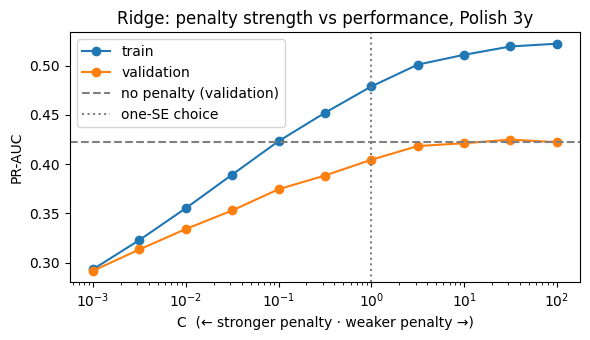

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ridge_table["C"], ridge_table["train_PR_AUC"], "o-", label="train")
ax.plot(ridge_table["C"], ridge_table["val_PR_AUC"], "o-", label="validation")
ax.axhline(unpen["val_PR_AUC"], color="grey", linestyle="--", label="no penalty (validation)")
ax.axvline(C_RIDGE, color="grey", linestyle=":", label="one-SE choice")
ax.set_xscale("log")
ax.set_xlabel("C  (← stronger penalty · weaker penalty →)")
ax.set_ylabel("PR-AUC")
ax.set_title("Ridge: penalty strength vs performance, Polish 3y")
ax.legend()
plt.tight_layout()
plt.show()

**What we found:**
- **Ridge never really beats no penalty.** The best ridge (C ≈ 32) scores 0.425 vs 0.422, which is the same within noise.
  The one-standard-error choice is **C = 1** (validation 0.404).
- **The penalty does close the gap:** 0.100 with no penalty → 0.074 at C = 1 → 0.002 at C = 0.001.
  Closing it costs score, though: at C = 0.001 validation falls to 0.292.
- **Ridge barely fixes the sign flips:** 32% at C = 1 vs 36% with no penalty. They only drop to 13% when the
  penalty is so strong that the model is much worse.

Ridge's limitation is that it keeps *every* near-copy column in and only makes them smaller. Spreading weight
over many near-copies doesn't make the model easier to explain.

## Step 7 — Lasso (L1 penalty)

**The idea:** add a penalty equal to the sum of the *absolute values* of the coefficients. This penalty
pushes weak coefficients to **exactly zero**, so the column is dropped. Lasso therefore **chooses**:
from a group of near-copies it tends to keep one and drop the rest.

C is chosen with the same one-standard-error rule.

In [10]:
lasso_table, lasso_coefs = tune(l1_ratio=1.0)
lasso_table.round(3)

,C,train_PR_AUC,val_PR_AUC,val_sd,gap,n_nonzero,sign_flips,flips_among_kept,converged
0,0.001,0.047,0.047,0.000,0.000,0.0,0.000,NaN,True
1,0.003,0.140,0.143,0.017,-0.003,2.0,0.000,0.000,True
2,0.010,0.267,0.271,0.030,-0.004,5.6,0.000,0.000,True
3,0.032,0.305,0.300,0.034,0.005,15.0,0.000,0.000,True
4,0.100,0.385,0.357,0.041,0.028,34.2,0.000,0.000,True
5,0.316,0.463,0.408,0.057,0.055,51.0,0.026,0.029,True
6,1.000,0.494,0.428,0.067,0.066,63.2,0.154,0.158,True
7,3.162,0.506,0.429,0.070,0.077,72.8,0.308,0.308,True
8,10.000,0.510,0.424,0.069,0.086,76.6,0.372,0.372,True
9,31.623,0.512,0.423,0.069,0.089,78.0,0.372,0.372,True


In [11]:
C_LASSO, C_LASSO_BEST = one_se_rule(lasso_table)
print(f"Best-scoring C: {C_LASSO_BEST:.4g} · one-standard-error C: {C_LASSO:.4g}")
lasso_table[lasso_table["C"].isin([C_LASSO, C_LASSO_BEST])].round(3)

Best-scoring C: 3.162 · one-standard-error C: 0.3162


,C,train_PR_AUC,val_PR_AUC,val_sd,gap,n_nonzero,sign_flips,flips_among_kept,converged
5,0.316,0.463,0.408,0.057,0.055,51.0,0.026,0.029,True
7,3.162,0.506,0.429,0.070,0.077,72.8,0.308,0.308,True


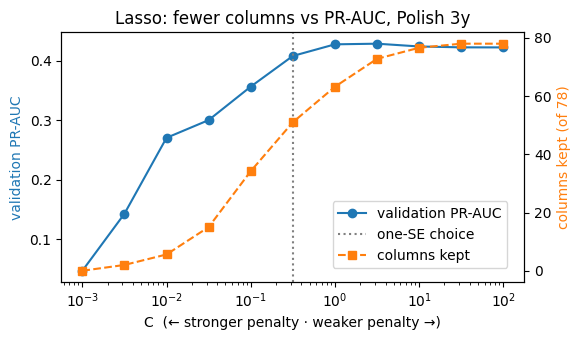

In [12]:
# Figure candidate: how many columns lasso keeps, and what it costs in PR-AUC
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(lasso_table["C"], lasso_table["val_PR_AUC"], "o-", color="tab:blue", label="validation PR-AUC")
ax1.axvline(C_LASSO, color="grey", linestyle=":", label="one-SE choice")
ax1.set_xscale("log")
ax1.set_xlabel("C  (← stronger penalty · weaker penalty →)")
ax1.set_ylabel("validation PR-AUC", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(lasso_table["C"], lasso_table["n_nonzero"], "s--", color="tab:orange", label="columns kept")
ax2.set_ylabel(f"columns kept (of {len(FEATURE_NAMES)})", color="tab:orange")
ax1.set_title("Lasso: fewer columns vs PR-AUC, Polish 3y")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.2))
plt.tight_layout()
plt.show()

**Which columns survive, and how reliably?** For the chosen C, count in how many of the 5 folds each column
was kept. Kept in 5 of 5 = a reliable choice; kept in 1 of 5 = luck.

The **family** is the start of the name (`prof`, `lev`, `act`, `liq`, `size`); the blank flags are their own family, `blank`.

In [13]:
def family(name):
    return name.split("_")[0]   # prof, lev, act, liq, size — or blank for the flags

coefs = lasso_coefs[C_LASSO]
kept = pd.DataFrame({
    "folds_kept": (np.abs(coefs) > 1e-8).sum(axis=0),
    "mean_coef": coefs.mean(axis=0),
    "family": [family(n) for n in FEATURE_NAMES],
}, index=FEATURE_NAMES)

stable = kept[kept["folds_kept"] == 5].sort_values("mean_coef", key=abs, ascending=False)
print(f"Kept in all 5 folds: {len(stable)} columns · kept in at least one fold: {(kept['folds_kept'] > 0).sum()}")
stable.head(15).round(3)   # the 15 largest effects

Kept in all 5 folds: 33 columns · kept in at least one fold: 70


,folds_kept,mean_coef,family
act_curr_liab_days_cogs,5,3.588,act
act_opex_st_liab,5,2.527,act
act_st_liab_days_cogs,5,-2.174,act
liq_quick_ratio,5,-1.124,liq
prof_ebitda_assets,5,0.771,prof
act_st_liab_days_sales,5,0.677,act
liq_current_ratio,5,0.569,liq
lev_constant_cap_assets,5,-0.486,lev
blank_act_sales_assets,5,0.392,blank
blank_lev_debt_to_op_cashflow,5,-0.383,blank


In [14]:
# Kept-in-all-folds columns by family, against how many columns each family has
fam = kept.groupby("family").agg(n_columns=("folds_kept", "size"),
                                 n_stable=("folds_kept", lambda f: (f == 5).sum()))
fam["share_kept"] = (fam["n_stable"] / fam["n_columns"]).round(2)
fam.sort_values("share_kept", ascending=False)

,n_columns,n_stable,share_kept
family,,,
size,1,1,1.00
act,14,9,0.64
blank,19,10,0.53
liq,9,3,0.33
lev,16,5,0.31
prof,19,5,0.26


**Reading the coefficients.** Columns are on the rank (bell-curve) scale, so a coefficient means: how much the
risk goes up when the ratio moves up by about one "step" in rank. Positive = higher ratio → more risk.
Negative = higher ratio → less risk.

**What we found:**
- **Lasso picks C = 0.316 and keeps about 51 of 78 columns** (validation 0.408). The very best C (3.16) keeps
  73 columns for 0.429, which is within noise of the simpler model.
- **Sign flips almost disappear: 3%** (3% also when counting only the columns lasso uses), down from 36%.
  This is the clearest gain of the week: the model now gives a stable answer about which way each ratio pushes.
- **33 columns are kept in all 5 folds;** 70 are kept at least once.
- **By family (share of the family kept in all 5 folds):** size 100% · activity 64% · blank flags 53% ·
  liquidity 33% · leverage 31% · **profitability 26%**. Profitability had the most near-copies in Week 1,
  and lasso keeps the fewest of them. Activity ratios (payment periods and turnover) and the blank
  flags carry the most signal.

**Readable signs:**
- `liq_quick_ratio` −1.12: more cash-like assets per unit of short-term debt → **safer**. ✔
- `lev_constant_cap_assets` −0.49: more long-term capital funding the assets → **safer**. ✔
- `liq_current_ratio` +0.57 next to the quick ratio: the two differ only by inventory. Holding the quick ratio
  fixed, a higher current ratio means a larger share of current assets is inventory. One reading is that
  liquidity that depends on inventory rather than cash and receivables is riskier.

**Signs that should *not* be read one at a time:**
- The three biggest coefficients, `act_curr_liab_days_cogs` (+3.59), `act_opex_st_liab` (+2.53) and
  `act_st_liab_days_cogs` (−2.17), belong to **one group of near-copies**: their rank correlations are 0.997–0.999.
  Lasso kept all three with large signs that partly cancel. It did **not** solve this overlap; the group
  should be read as one signal ("how long short-term debts take to pay off compared with costs").
- `size_log_assets`, `lev_interest_coverage` and `prof_ebitda_assets` come out *positive* (more → riskier),
  but in the raw data bankrupt firms have *lower* values of all three. These signs are bent by
  neighbouring columns. Read **families**, not single coefficients.

## Step 8 — Elastic net (half lasso, half ridge)

**The idea:** lasso picks **one** column from a group of near-copies, almost at random; ridge keeps the whole
group. Elastic net mixes the two penalties (`l1_ratio = 0.5`), so it can drop useless columns like lasso
while keeping groups of correlated columns together like ridge.

In [15]:
enet_table, enet_coefs = tune(l1_ratio=0.5)
C_ENET, C_ENET_BEST = one_se_rule(enet_table)
print(f"One-standard-error C: {C_ENET:.4g}")
enet_table.round(3)

One-standard-error C: 0.3162


,C,train_PR_AUC,val_PR_AUC,val_sd,gap,n_nonzero,sign_flips,flips_among_kept,converged
0,0.001,0.140,0.143,0.017,-0.003,2.0,0.000,0.000,True
1,0.003,0.237,0.244,0.031,-0.007,5.8,0.000,0.000,True
2,0.010,0.290,0.291,0.030,-0.001,12.6,0.000,0.000,True
3,0.032,0.345,0.327,0.038,0.019,24.2,0.000,0.000,True
4,0.100,0.408,0.370,0.045,0.038,45.2,0.000,0.000,True
5,0.316,0.454,0.396,0.055,0.059,60.8,0.064,0.067,True
6,1.000,0.482,0.414,0.065,0.069,70.4,0.218,0.218,True
7,3.162,0.499,0.421,0.068,0.078,75.8,0.333,0.333,True
8,10.000,0.507,0.421,0.069,0.086,77.8,0.372,0.372,True
9,31.623,0.511,0.423,0.070,0.088,78.0,0.372,0.372,True


**What we found:** with the same rule it picks **C = 0.316**, keeps about **61 columns** (10 more than
lasso), scores 0.396 and flips 6%. It lands between ridge and lasso on every measure. It doesn't beat lasso
here: the extra columns it keeps don't add score, and they bring back a few flips.

## Step 9 — Final comparison on the test set

Each model is refitted on all the training companies with its chosen C, then scored **once** on the test set.

The test set has only 99 bankrupt firms, so one score is noisy. To show how noisy, we **re-draw the test set
1,000 times** (bootstrap) and report the range that holds 95% of the re-scores.

In [16]:
final_models = {
    "no penalty":                    (make_model(),                          unpen["coefs"]),
    f"ridge (C={C_RIDGE:.3g})":       (make_model(C=C_RIDGE, l1_ratio=0.0), ridge_coefs[C_RIDGE]),
    f"lasso (C={C_LASSO:.3g})":       (make_model(C=C_LASSO, l1_ratio=1.0), lasso_coefs[C_LASSO]),
    f"elastic net (C={C_ENET:.3g})":  (make_model(C=C_ENET, l1_ratio=0.5),  enet_coefs[C_ENET]),
}

# Only 99 bankrupt firms in the test set, so each test score is noisy.
# Bootstrap: re-draw the test set 1,000 times (with replacement) and re-score, to get a 95% range.
rng = np.random.default_rng(0)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
yt = y_test.to_numpy()

rows, boot_scores = [], {}
for name, (model, cv_coefs) in final_models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    tr = average_precision_score(y_train, model.predict_proba(X_train)[:, 1])
    te = average_precision_score(yt, p)
    boot_scores[name] = np.array([average_precision_score(yt[i], p[i]) for i in boot_idx])
    lo, hi = np.percentile(boot_scores[name], [2.5, 97.5])
    rows.append({"model": name, "columns_used": int((np.abs(model[-1].coef_) > 1e-8).sum()),
                 "train_PR_AUC": tr, "test_PR_AUC": te, "test_95%_range": f"{lo:.3f}–{hi:.3f}",
                 "gap": tr - te, "test_lift": te / y_test.mean(),
                 "sign_flips_cv": sign_flips(cv_coefs), "flips_among_kept": sign_flips_kept(cv_coefs)})
comparison = pd.DataFrame(rows)
comparison.round(3)

,model,columns_used,train_PR_AUC,test_PR_AUC,test_95%_range,gap,test_lift,sign_flips_cv,flips_among_kept
0,no penalty,78,0.514,0.459,0.366–0.573,0.055,9.658,0.359,0.359
1,ridge (C=1),78,0.469,0.485,0.386–0.596,-0.016,10.206,0.321,0.321
2,lasso (C=0.316),54,0.458,0.496,0.397–0.607,-0.038,10.449,0.026,0.029
3,elastic net (C=0.316),62,0.450,0.477,0.380–0.583,-0.026,10.032,0.064,0.067


In [17]:
# Is each penalty really better than no penalty on the test set?
# Same 1,000 re-draws for every model, so we can compare them draw by draw.
base = boot_scores["no penalty"]
for name, s in boot_scores.items():
    if name == "no penalty":
        continue
    d = s - base
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"{name:24s} minus no penalty: {d.mean():+.3f}  (95% range {lo:+.3f} to {hi:+.3f})")

ridge (C=1)              minus no penalty: +0.023  (95% range -0.030 to +0.084)
lasso (C=0.316)          minus no penalty: +0.032  (95% range -0.025 to +0.093)
elastic net (C=0.316)    minus no penalty: +0.013  (95% range -0.048 to +0.077)


**What we found:**

| Model | Columns | Test PR-AUC (95% range) | Lift | Sign flips |
|---|---|---|---|---|
| No penalty | 78 | 0.459 (0.37–0.57) | 9.7× | 36% |
| Ridge, C = 1 | 78 | 0.485 (0.39–0.60) | 10.2× | 32% |
| **Lasso, C = 0.316** | **54** | **0.496 (0.40–0.61)** | **10.4×** | **3%** |
| Elastic net, C = 0.316 | 62 | 0.477 (0.38–0.58) | 10.0× | 6% |

1. **Did a penalty improve the score?** Not provably. Lasso is highest, but its lead over no penalty (+0.032)
   has a 95% range of −0.025 to +0.093, which includes zero. The same holds for ridge and elastic net.
2. **Did the train–test gap shrink?** Yes: no penalty 0.055; every penalised model has a gap at or below zero.
   A negative gap means the test firms happened to be slightly easier to rank, which is chance.
3. **Did the model become easier to explain?** Yes, and this is the real result. Lasso gets **the same score with
   24 fewer columns, and sign flips fall from 36% to 3%.**

The penalty buys a **simpler, more stable** model, not a more accurate one.

## Step 10 — RQ2: does the chosen family change with how far ahead we look?

**What we do:** run the same lasso on each of the five horizon files (1 to 5 years ahead) and count how
much of each family it keeps.

- **Same strictness everywhere.** scikit-learn *adds up* the error over companies, so the same C is a weaker
  penalty on a bigger file. C was chosen on folds of about 6,666 companies, so each horizon uses
  C × 6,666 ÷ (its number of companies). That keeps the penalty per company the same.
- **Share, not count.** Families have different sizes (profitability 19 columns, liquidity 9), so the table
  shows the *share* of each family that is kept.
- Each horizon is fitted on all its companies: the aim is to **describe** what lasso picks, not to score it.
- Horizons are never mixed (Week 1, Step 1).

In [18]:
# C was chosen on training folds of about 6,666 firms. scikit-learn ADDS UP the error over firms,
# so the same C is a weaker penalty on a bigger file. Scaling C by (6,666 ÷ firms) keeps the
# penalty per firm the same at every horizon.
N_TUNE = len(X_train) * 4 / 5
family_size = pd.Series([family(n) for n in COLUMNS]).value_counts()

by_horizon, info = {}, {}
for h in range(1, 6):
    df = add_blank_flags(load_polish(h))   # same flag columns as the 3-year file
    C_h = C_LASSO * N_TUNE / len(df)
    m = make_model(C=C_h, l1_ratio=1.0).fit(df[COLUMNS], df["class"])
    kept_h = pd.Series([family(n) for n, b in zip(COLUMNS, m[-1].coef_[0]) if abs(b) > 1e-8])
    by_horizon[f"{h}y"] = kept_h.value_counts()
    info[f"{h}y"] = {"firms": len(df), "bankrupt_rate": round(df["class"].mean(), 4),
                     "C_used": round(C_h, 3), "columns_kept": len(kept_h)}

print(pd.DataFrame(info), "\n")
# Share of each family's columns that lasso keeps (families have different sizes, so raw counts mislead)
horizon_counts = pd.DataFrame(by_horizon).reindex(family_size.index).fillna(0).astype(int)
horizon_share = horizon_counts.div(family_size, axis=0).round(2)
horizon_share.insert(0, "family_size", family_size)
horizon_share

                      1y         2y          3y          4y        5y
firms          5850.0000  9710.0000  10416.0000  10083.0000  6945.000
bankrupt_rate     0.0697     0.0528      0.0473      0.0395     0.039
C_used            0.3600     0.2170      0.2020      0.2090     0.304
columns_kept     56.0000    51.0000     48.0000     50.0000    47.000 



,family_size,1y,2y,3y,4y,5y
prof,19,0.79,0.58,0.58,0.42,0.79
blank,19,0.74,0.63,0.68,0.68,0.53
lev,16,0.69,0.56,0.56,0.62,0.44
act,14,0.71,0.86,0.71,0.79,0.71
liq,9,0.56,0.67,0.44,0.78,0.44
size,1,1.00,1.00,1.00,1.00,1.00


**What we found:**
- **Activity ratios are chosen at every horizon** (71–86% kept), and so are the size column and the blank
  flags (53–74%). These look like the stable core signal.
- **No clean trend with distance.** Profitability is kept most at 1 and 5 years (79%) and least at 4 years
  (42%); liquidity jumps between 44% and 78%; leverage is lowest at 5 years (44%).
- **Caution:** each horizon was fitted once. Liquidity has only 9 columns, so 44% vs 78% is 4 vs 7 columns,
  well within what a different sample could change. Week 3 (PCR loadings) and Week 6 (random-forest
  importance) will show whether these differences are real.

**Answer to RQ2 so far:** activity ratios and blank patterns carry the signal at every horizon. Lasso
gives no clear sign that the important family changes with horizon.

## Step 11 — Contrast: Taiwanese data, where bankrupt firms are scarce

The proposal argued a penalty is **essential** when there are few bankrupt firms per column.

| | Bankrupt firms (training) | Columns | Per column |
|---|---|---|---|
| Taiwanese | 176 | 94 | **1.9** |
| Polish 3y | 394 | 78 | 5.1 |

(The usual rule of thumb asks for at least 10.)

**Same procedure:** no penalty vs ridge across C, 5 folds on an 80% training split.

**Caveat:** 23 Taiwanese columns contain values above 10⁹ that look like placeholder codes. The rank transform
turns them into "highest" so they cannot distort the fit; proper cleaning is Week 4's job.

In [19]:
tw = pd.read_csv(DATA / "taiwanese_bankruptcy.csv")
TW_FEATURES = [c for c in tw.columns if c not in ("Bankrupt?", "Net Income Flag")]   # Net Income Flag is constant
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    tw[TW_FEATURES], tw["Bankrupt?"], test_size=0.2, stratify=tw["Bankrupt?"], random_state=42)
print(f"{len(TW_FEATURES)} ratios · {yt_train.sum()} bankrupt in training "
      f"→ {yt_train.sum() / len(TW_FEATURES):.1f} per ratio")

tw_rows = []
for C in [np.inf] + list(C_GRID):
    r = cross_validate(make_model(C=C, l1_ratio=0.0), Xt_train, yt_train, cv=cv,
                       scoring="average_precision", return_train_score=True, n_jobs=-1)
    tw_rows.append({"C": "no penalty" if np.isinf(C) else round(C, 4),
                    "train_PR_AUC": r["train_score"].mean(), "val_PR_AUC": r["test_score"].mean(),
                    "val_sd": r["test_score"].std(),
                    "gap": r["train_score"].mean() - r["test_score"].mean()})
pd.DataFrame(tw_rows).round(3)

94 ratios · 176 bankrupt in training → 1.9 per ratio


,C,train_PR_AUC,val_PR_AUC,val_sd,gap
0,no penalty,0.589,0.381,0.050,0.208
1,0.001,0.394,0.384,0.038,0.009
2,0.0032,0.427,0.402,0.032,0.025
3,0.01,0.474,0.414,0.024,0.060
4,0.0316,0.513,0.423,0.025,0.090
5,0.1,0.540,0.426,0.026,0.114
6,0.3162,0.560,0.414,0.032,0.146
7,1.0,0.572,0.399,0.036,0.173
8,3.1623,0.582,0.396,0.031,0.186
9,10.0,0.586,0.391,0.042,0.195


**What we found:** here the penalty clearly helps, unlike on the Polish data.
- **No penalty memorises:** train 0.589, validation 0.381, a gap of **0.208**, twice the Polish gap (0.100).
- **Ridge at C = 0.1 lifts validation to 0.426** (+0.045). It wins in 4 of 5 folds, and the fold-to-fold
  spread halves (0.050 → 0.026). The gap falls to 0.114.
- On Polish data the best ridge added only +0.003.

**Fewer bankrupt firms per column → a penalty matters more.** With 1.9 per column the unpenalised model
mostly learns noise; with 5.1 per column it gets away with it.

## Expected vs unexpected

The expectations come from documents written **before** this notebook ran: the capstone proposal and the
Week 1 conclusions.

**Expected**
- Unpenalised models "cannot be fitted stably at all" (proposal) → it fitted fine and predicted as well as any
  penalty (test 0.459 vs 0.48–0.50), but its **explanation** was unstable (36% sign flips) → **partly right**:
  unstable explanation, not prediction.
- Regularisation is mandatory when bankrupt firms per column are low (proposal) → Taiwanese (1.9 per column):
  ridge +0.045; Polish (about 5 per column): +0.003 → **right for Taiwanese, not for Polish**.
- Lasso will keep only one or two profitability ratios (Week 1 conclusions) → profitability had the lowest share
  kept (26%), but 5 ratios, not 1–2 → **direction right, size wrong**.
- A penalty reduces overfitting (course theory) → train–test gap 0.100 → about 0 → **confirmed**.

**Unexpected**
- Debt ÷ assets, a classic bankruptcy ratio (Altman), was dropped by lasso: other leverage ratios already carry
  its information.
- Scaling mattered more than any penalty (validation 0.273 → 0.422).
- *Which* values are blank is among the strongest signals (validation 0.288 → 0.422).

## Conclusions

1. **Scaling:** turning ratios into ranks (quantile transform) lifted validation PR-AUC from 0.273 to 0.422.
   Taming extreme values mattered more than any penalty.
2. **Blank flags:** adding the blank-pattern flags lifted PR-AUC from 0.288 to 0.422. *Which* values a firm
   leaves blank is one of the strongest predictors.
3. **No penalty:** validation 0.422, gap 0.100, and **36% of columns flip sign** between folds. The model can't
   say which way many ratios push.
4. **Ridge:** never beats no penalty (best 0.425). It shrinks the gap but keeps every near-copy column, and
   flips stay around 32%.
5. **Lasso:** keeps about 51 of 78 columns at C = 0.316 for nearly the same score, and **flips fall to 3%**.
   Kept most: size, activity, blank flags. Kept least: profitability (26%), the family with the most
   near-copies.
6. **Elastic net:** sits between ridge and lasso (61 columns, 6% flips) with no extra benefit.
7. **Test set:** all four models score 0.46–0.50 (9.7–10.4× better than random); the differences are within noise.
   **The penalty buys simplicity and stability, not accuracy.**
8. **RQ2 across horizons:** activity ratios and empty-box patterns are chosen at all five horizons. There is no
   clear shift with distance; the swings in liquidity and profitability are a few columns and need Weeks 3 and 6 to confirm.
9. **Polish vs Taiwanese:** with 1.9 bankrupt firms per column (Taiwanese), ridge improves validation by 0.045
   and halves the noise; with 5.1 (Polish) it adds nothing. **A penalty is essential when bankrupt firms are scarce.**
10. **What the hyperparameter means:** lasso C = 0.316 (penalty λ ≈ 3.2) keeps about two-thirds of the columns.
    Making it stricter (C = 0.1) keeps 34 columns and drops validation to 0.357; looser (C = 3.16) keeps 73 for
    0.429. Around C = 0.3 is the point where dropping more columns starts to cost real score.

**Limits:** lasso still kept a group of three near-identical activity ratios with opposing signs, and several
single signs run against the raw data. Read families, not individual coefficients.